In [1]:

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Locate project directory
project_root = Path.cwd()

if not (project_root / "data" / "processed").exists():
    project_root = project_root.parent

# Define dataset and model paths
dataset_path = project_root / "data" / "processed" / "nyc_311_cleaned.csv"
models_path = project_root / "models"

print("Project directory:", project_root)
print("Dataset exists:", dataset_path.exists())
print("Models directory exists:", models_path.exists())

# Load cleaned dataset
df = pd.read_csv(dataset_path)

print("\nDataset loaded successfully!")
print("Dataset shape:", df.shape)
print("\nDataset columns:")
print(df.columns.tolist())
print("\nMissing values:")
print(df.isnull().sum())


Project directory: c:\Users\MY PC\Documents\5th Semester\All Projects\CivicFix
Dataset exists: True
Models directory exists: True

Dataset loaded successfully!
Dataset shape: (20000, 11)

Dataset columns:
['agency', 'complaint_type', 'descriptor', 'incident_zip', 'borough', 'location_type', 'target', 'created_month', 'created_weekday', 'created_hour', 'split_date']

Missing values:
agency             0
complaint_type     0
descriptor         0
incident_zip       0
borough            0
location_type      0
target             0
created_month      0
created_weekday    0
created_hour       0
split_date         0
dtype: int64


TARGET CLASS DISTRIBUTION
target
0    16330
1     3670
Name: count, dtype: int64

TARGET CLASS PERCENTAGE
target
0    81.65
1    18.35
Name: proportion, dtype: float64


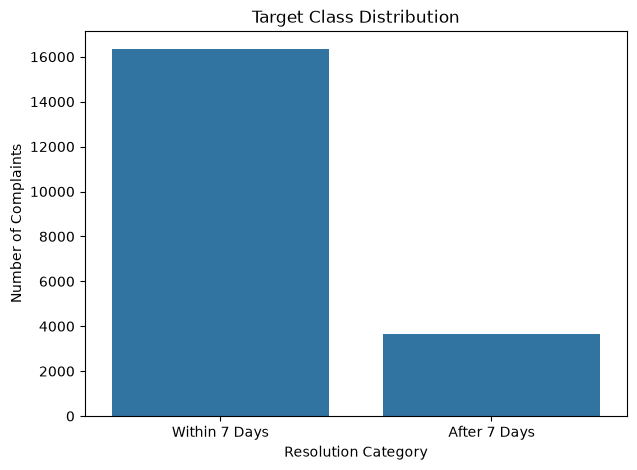

In [2]:

# Count each target class
print("TARGET CLASS DISTRIBUTION")

print(df["target"].value_counts().sort_index())

# Calculate percentages
print("\nTARGET CLASS PERCENTAGE")

print(
    df["target"].value_counts(normalize=True)
    .sort_index() * 100
)

# Visualize class distribution
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="target")

plt.title("Target Class Distribution")
plt.xlabel("Resolution Category")
plt.ylabel("Number of Complaints")
plt.xticks([0, 1], ["Within 7 Days", "After 7 Days"])

plt.show()


In [3]:
# Sort records chronologically
eval_df = df.sort_values(
    "split_date"
).reset_index(drop=True)

# Same chronological split as Sneha
train_df = eval_df.iloc[:16000].copy()
test_df = eval_df.iloc[16000:].copy()

# Features used by Sneha
feature_columns = [
    "agency",
    "complaint_type",
    "descriptor",
    "incident_zip",
    "borough",
    "location_type",
    "created_month",
    "created_weekday",
    "created_hour"
]

# Prepare training and testing data
X_train = train_df[feature_columns].copy()
y_train = train_df["target"].copy()

X_test = test_df[feature_columns].copy()
y_test = test_df["target"].copy()

# Display results
print("TEST DATA PREPARATION")
print("---------------------")
print("Training records:", len(train_df))
print("Testing records:", len(test_df))

print("\nTesting features shape:", X_test.shape)
print("Testing target shape:", y_test.shape)

print("\nTesting target distribution:")
print(y_test.value_counts().sort_index())

print("\nTesting date range:")
print(test_df["split_date"].min())
print("to")
print(test_df["split_date"].max())



TEST DATA PREPARATION
---------------------
Training records: 16000
Testing records: 4000

Testing features shape: (4000, 9)
Testing target shape: (4000,)

Testing target distribution:
target
0    3386
1     614
Name: count, dtype: int64

Testing date range:
2024-12-03 12:33:57
to
2025-12-23 09:29:32


In [4]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, classification_report

# Create baseline model
baseline = DummyClassifier(strategy="most_frequent")

# Train only on training labels
baseline.fit(X_train, y_train)

# Predict on unseen testing data
baseline_predictions = baseline.predict(X_test)

# Evaluate baseline
print("MAJORITY CLASS BASELINE")
print("-----------------------")

print("Accuracy:", accuracy_score(y_test, baseline_predictions))

print("\nClassification Report:")
print(classification_report(
    y_test,
    baseline_predictions,
    zero_division=0
))


MAJORITY CLASS BASELINE
-----------------------
Accuracy: 0.8465

Classification Report:
              precision    recall  f1-score   support

           0       0.85      1.00      0.92      3386
           1       0.00      0.00      0.00       614

    accuracy                           0.85      4000
   macro avg       0.42      0.50      0.46      4000
weighted avg       0.72      0.85      0.78      4000



In [5]:
import joblib

# Load corrected trained models
logistic_model = joblib.load(
    models_path / "logistic_regression.pkl"
)

random_forest_model = joblib.load(
    models_path / "random_forest.pkl"
)

gradient_boosting_model = joblib.load(
    models_path / "gradient_boosting.pkl"
)

print("All three models loaded successfully!")

print("\nLogistic Regression:", type(logistic_model))
print("Random Forest:", type(random_forest_model))
print("Gradient Boosting:", type(gradient_boosting_model))


All three models loaded successfully!

Logistic Regression: <class 'sklearn.pipeline.Pipeline'>
Random Forest: <class 'sklearn.pipeline.Pipeline'>
Gradient Boosting: <class 'sklearn.pipeline.Pipeline'>


In [6]:
# Generate predictions using all three models

logistic_predictions = logistic_model.predict(X_test)

random_forest_predictions = random_forest_model.predict(X_test)

gradient_boosting_predictions = gradient_boosting_model.predict(X_test)

print("Predictions generated successfully!")

print("Logistic Regression:", len(logistic_predictions))
print("Random Forest:", len(random_forest_predictions))
print("Gradient Boosting:", len(gradient_boosting_predictions))

Predictions generated successfully!
Logistic Regression: 4000
Random Forest: 4000
Gradient Boosting: 4000


In [7]:

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

models = {
    "Logistic Regression": logistic_predictions,
    "Random Forest": random_forest_predictions,
    "Gradient Boosting": gradient_boosting_predictions
}

results = []

for name, predictions in models.items():

    accuracy = accuracy_score(y_test, predictions)
    precision = precision_score(y_test, predictions, zero_division=0)
    recall = recall_score(y_test, predictions, zero_division=0)
    f1 = f1_score(y_test, predictions, zero_division=0)

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

    print("\n", name)
    print("Accuracy:", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall:", round(recall, 4))
    print("F1 Score:", round(f1, 4))

results_df = pd.DataFrame(results)

print("\nMODEL COMPARISON TABLE")
display(results_df.round(4))



 Logistic Regression
Accuracy: 0.854
Precision: 0.5139
Recall: 0.9007
F1 Score: 0.6544

 Random Forest
Accuracy: 0.8808
Precision: 0.5788
Recall: 0.8192
F1 Score: 0.6784

 Gradient Boosting
Accuracy: 0.8878
Precision: 0.6087
Recall: 0.7524
F1 Score: 0.673

MODEL COMPARISON TABLE


,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.8540,0.5139,0.9007,0.6544
1,Random Forest,0.8808,0.5788,0.8192,0.6784
2,Gradient Boosting,0.8878,0.6087,0.7524,0.6730


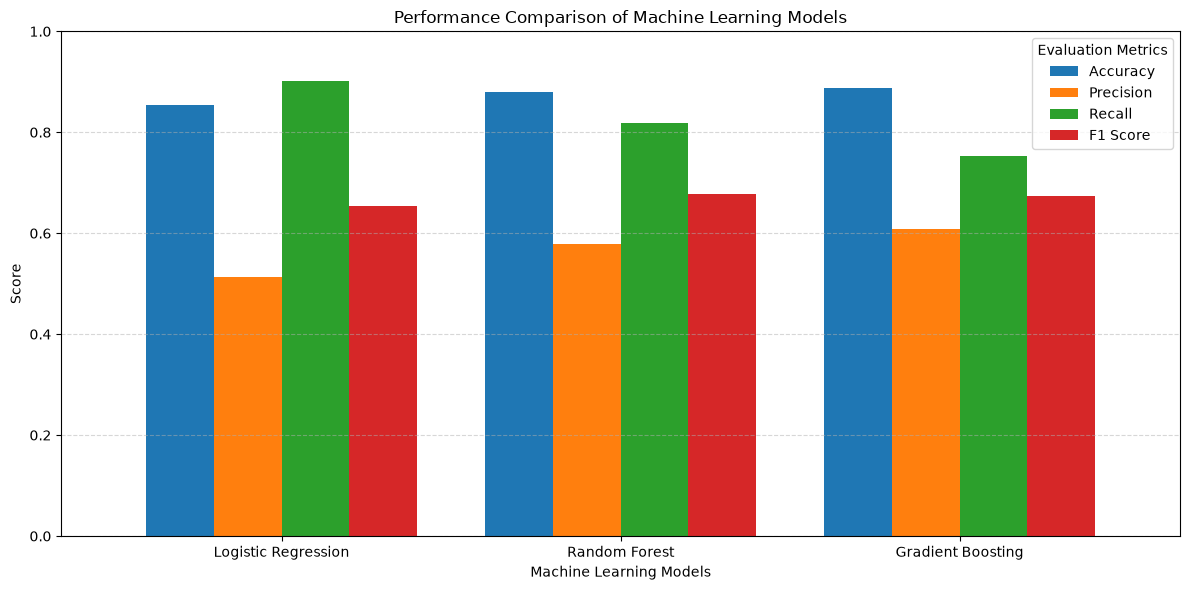

In [8]:

# Model Performance Comparison Graph

metrics = ["Accuracy", "Precision", "Recall", "F1 Score"]

results_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8
)

plt.title("Performance Comparison of Machine Learning Models")
plt.xlabel("Machine Learning Models")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title="Evaluation Metrics")
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()


In [9]:

from sklearn.metrics import confusion_matrix
import pandas as pd

error_analysis = []

for name, predictions in models.items():

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        predictions,
        labels=[0, 1]
    ).ravel()

    error_analysis.append({
        "Model": name,
        "True Negatives": tn,
        "False Positives": fp,
        "False Negatives": fn,
        "True Positives": tp
    })

error_analysis_df = pd.DataFrame(error_analysis)

print("FALSE POSITIVE AND FALSE NEGATIVE ANALYSIS")
display(error_analysis_df)


FALSE POSITIVE AND FALSE NEGATIVE ANALYSIS


,Model,True Negatives,False Positives,False Negatives,True Positives
0,Logistic Regression,2863,523,61,553
1,Random Forest,3020,366,111,503
2,Gradient Boosting,3089,297,152,462


Logistic Regression
[[2863  523]
 [  61  553]]


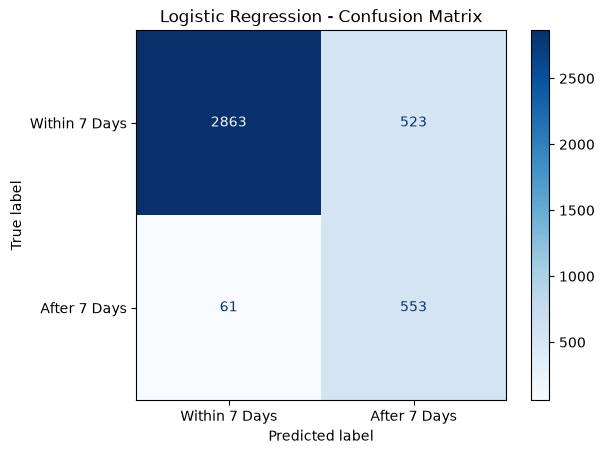

Random Forest
[[3020  366]
 [ 111  503]]


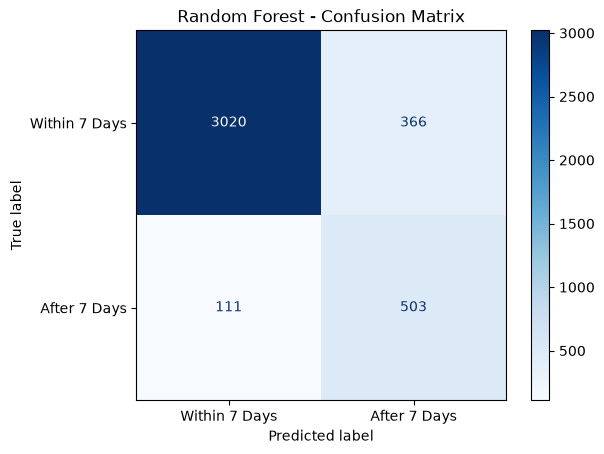

Gradient Boosting
[[3089  297]
 [ 152  462]]


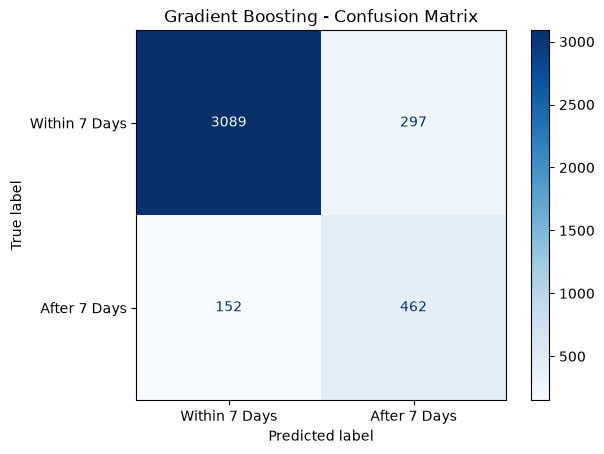

In [10]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

models = {
    "Logistic Regression": logistic_predictions,
    "Random Forest": random_forest_predictions,
    "Gradient Boosting": gradient_boosting_predictions
}

for name, predictions in models.items():
    cm = confusion_matrix(y_test, predictions)

    print(name)
    print(cm)

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Within 7 Days", "After 7 Days"]
    )

    disp.plot(cmap="Blues")
    plt.title(name + " - Confusion Matrix")
    plt.show()

In [1]:
import pandas as pd

df = pd.read_csv("../data/processed/nyc_311_cleaned.csv")

print(df.columns.tolist())
print(df.shape)

['agency', 'complaint_type', 'descriptor', 'incident_zip', 'borough', 'location_type', 'target', 'created_month', 'created_weekday', 'created_hour', 'split_date']
(20000, 11)


In [2]:
import joblib

# Sort records chronologically
df["split_date"] = pd.to_datetime(df["split_date"])
df = df.sort_values("split_date").reset_index(drop=True)

# Select the last 4,000 records
test_df = df.iloc[16000:].copy()

# Select the 9 model input features
features = [
    "agency",
    "complaint_type",
    "descriptor",
    "incident_zip",
    "borough",
    "location_type",
    "created_month",
    "created_weekday",
    "created_hour"
]

X_test = test_df[features]

# Load all three trained models
models = {
    "Logistic Regression": joblib.load("../models/logistic_regression.pkl"),
    "Random Forest": joblib.load("../models/random_forest.pkl"),
    "Gradient Boosting": joblib.load("../models/gradient_boosting.pkl")
}

# Find records predicted as delayed by at least one model
results = {}

for name, model in models.items():
    results[name] = model.predict(X_test)

prediction_df = test_df[features + ["target"]].copy()

for name, predictions in results.items():
    prediction_df[name] = predictions

delayed_records = prediction_df[
    (prediction_df["Logistic Regression"] == 1) |
    (prediction_df["Random Forest"] == 1) |
    (prediction_df["Gradient Boosting"] == 1)
]

print("Number of delayed predictions:", len(delayed_records))

display(delayed_records.head(10))

Number of delayed predictions: 1090


,agency,complaint_type,descriptor,incident_zip,borough,location_type,created_month,created_weekday,created_hour,target,Logistic Regression,Random Forest,Gradient Boosting
16000,DOB,Plumbing,Gas Hook-Up/Piping - Illegal Or Defective,10472,BRONX,Unknown,12,Tuesday,12,0,1,1,0
16001,HPD,PLUMBING,WATER SUPPLY,11208,BROOKLYN,RESIDENTIAL BUILDING,12,Tuesday,12,1,1,1,1
16002,HPD,UNSANITARY CONDITION,PESTS,10459,BRONX,RESIDENTIAL BUILDING,12,Tuesday,12,1,1,1,1
16006,DSNY,Illegal Dumping,Removal Request,11208,BROOKLYN,Sidewalk,12,Tuesday,12,0,1,1,0
16014,DOHMH,Food Establishment,Pet/Animal,10065,MANHATTAN,Other (Explain Below),12,Tuesday,12,1,1,1,1
16015,DOB,Electrical,Electrical Wiring Defective/Exposed,11420,QUEENS,Unknown,12,Tuesday,12,0,1,1,0
16018,DOHMH,Food Establishment,Rodents/Insects/Garbage,11209,BROOKLYN,Restaurant/Bar/Deli/Bakery,12,Tuesday,12,1,1,1,1
16028,HPD,WATER LEAK,HEAVY FLOW,10467,BRONX,RESIDENTIAL BUILDING,12,Tuesday,13,1,1,1,1
16029,HPD,ELECTRIC,OUTLET/SWITCH,10467,BRONX,RESIDENTIAL BUILDING,12,Tuesday,13,1,1,1,1
16030,HPD,PAINT/PLASTER,WALL,10467,BRONX,RESIDENTIAL BUILDING,12,Tuesday,13,1,1,1,1


In [3]:
within_7_days = prediction_df[prediction_df["target"] == 0]

display(within_7_days.head(10))

,agency,complaint_type,descriptor,incident_zip,borough,location_type,created_month,created_weekday,created_hour,target,Logistic Regression,Random Forest,Gradient Boosting
16000,DOB,Plumbing,Gas Hook-Up/Piping - Illegal Or Defective,10472,BRONX,Unknown,12,Tuesday,12,0,1,1,0
16003,NYPD,Blocked Driveway,Partial Access,11372,QUEENS,Street/Sidewalk,12,Tuesday,12,0,0,0,0
16004,HPD,HEAT/HOT WATER,ENTIRE BUILDING,10452,BRONX,RESIDENTIAL BUILDING,12,Tuesday,12,0,0,0,0
16005,NYPD,Blocked Driveway,No Access,11218,BROOKLYN,Street/Sidewalk,12,Tuesday,12,0,0,0,0
16006,DSNY,Illegal Dumping,Removal Request,11208,BROOKLYN,Sidewalk,12,Tuesday,12,0,1,1,0
16007,NYPD,Illegal Parking,Posted Parking Sign Violation,11432,QUEENS,Street/Sidewalk,12,Tuesday,12,0,0,0,0
16008,NYPD,Drug Activity,Use Outside,11355,QUEENS,Street/Sidewalk,12,Tuesday,12,0,0,0,0
16009,DSNY,Derelict Vehicles,Derelict Vehicles,10017,MANHATTAN,Street,12,Tuesday,12,0,0,0,0
16010,NYPD,Drug Activity,Use Indoor,11101,QUEENS,Hallway,12,Tuesday,12,0,0,0,0
16011,NYPD,Illegal Parking,Posted Parking Sign Violation,11203,BROOKLYN,Street/Sidewalk,12,Tuesday,12,0,0,0,0
